# CatBoost: что дали три дополнительных признака

Готовые результаты и анализ четырёх вариантов CatBoost: исходные признаки и исходные + три быстрых, с Clock и Cosine.

**Обучать ничего не нужно.** Таблицы и предсказания уже включены в ноутбук. Он работает самостоятельно, в том числе в Colab; достаточно NumPy, pandas, matplotlib и scikit-learn. Рисунки уже показаны ниже. Для редактирования подписи меняются в ячейке `TEXTS` или непосредственно в ячейках построения.

## Как получены результаты

- 31 участник, 25 481 эпоха по 30 секунд; сон / бодрствование.
- 31 разбиение leave-one-subject-out: тестовый участник полностью исключён из обучения.
- 100 деревьев, глубина 4, learning_rate=0,1, l2_leaf_reg=3, random_seed=0, веса классов balanced.
- Порог вероятности сна **0,5**; сглаживания предсказаний нет.
- Это текущая конфигурация `FAST=True`, но проверка выполнена на всех участниках, без сокращения выборки. Поиска гиперпараметров не было.
- Финальные веса на всех участниках сохранялись отдельно и не использовались для получения этих оценок.


In [1]:
# Подписи графиков и названия метрик можно редактировать здесь.
TEXTS = {
    "base": "Исходные",
    "fast": "+3 быстрых",
    "auc": "ROC AUC",
    "kappa": "Cohen κ",
    "accuracy": "Accuracy",
    "sleep_correct": "Сон распознан",
    "wake_correct": "Бодрствование распознано",
    "means_title": "CatBoost · средние по участникам · LOSO, порог 0,5",
    "delta_title": "Изменение κ у каждого участника: +3 быстрых − исходные",
    "roc_title": "ROC · объединённые тестовые эпохи",
    "pr_title": "Precision–Recall для бодрствования",
    "confusion_title": "Ошибки при фиксированном пороге 0,5",
}
COLORS = {"base": "#64748b", "fast": "#0f766e"}


In [2]:
import base64, gzip, io, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix
from pathlib import Path
EXPORT_DIR = Path("catboost_analysis_exports")
EXPORT_DIR.mkdir(exist_ok=True)
TABLE_PAYLOAD = "H4sIALrYzGoC/81dy24jSXb9FUFb9yPeD3sz8HjhjQHDgFeGISQzk11yq0RBVPWg0SjA9na+xgv/x/QfzTmRpJgRGdHJYmUbLqlYKpIi88Z9nfvkL/cv3evbY//40j2/PXwc314f++P939792y/3+7F7+/Q6PhzHN9xx/0+Ht8fD8zd3//gv39z98enQ/3j/zd398dPuP8aej2srolUG940vh/4DX8NIi/92n3r8LL6LVjotvTjf4qEfu5eXLj3orLfOWSO9dN4ZvkzX959eu/7n6ZclHlbOCieUEZG/fHwax5eH/vD6Ol0AnqSlVNF4Z4MRSuE5f+p+HLOnBOFdVPp86z9/c/elhFqplUlXcCHU6TmhIkYprVF4C6NNRqfSIcioQ5TGaJ1eJaPTK41flNI5LZxr0OmF1doZ5fAq0mpZIzS64O0N1Em8rVVhTl2QPqNOCamDliJIK3PqcC3KqyCDFiGEaEvqgrPaSRy7lOkl6lyUeG1vpRTGOmtNjTqcDk7WB+VEcNHexEYTgxN6Tqg3ORuF0+CXM4HMygg1JgQBMVA+eHBjIa6gzUPMlTIUZheqhAaoi9Y4LiGMn2R6QajHSRjoRAw4MSVuIVQ5jWsVc0KjCXNCtQNLBc5Te/ykcsWEKErtTTAyRLGQVxxSMJTpAF6ZBj+9nX3VyQzBydnNLWTaGMCKTHCtnJMJ2xCjkAoyBVuSUSltNA73mqikV2ZBZrAhhmjAcOEg9q7Bz+jBci2UtEF5XbU/0G+YKAnxAM9tuEVwoTlGZYRGb+aERgHFCOCkxnUnVs9UNEQVhHIe0m2EjQuGWumN1R6H6Xx0vs5SKwOE0noIJyQnVA2QwVP8++0tlEpjrY655No5pTAA3sMIOthBlZzNhVBtLUQzxoB/QM2So94Y2OcAAcYx1emEXDsRJd4U7gQCUDVFwkuj8Aqn2xvoxBkGWNPMo0yu4UQn3JnT0Ay4Ph2jymUXZkGG4E002ouQ1Dd3KdJ7A59jDQj1suFR4HYhEEbjNKdLqbhOK8HI8626gdAYYUtM5lzgCjKMEAIuFITAgcgCI0D5IJghevgHOOGldwF4gHjTM4FZsm50k2CTqxF8UzXRld+Jm2TVQExyvxnm8Mdb4eEx+KbJe+U8lNE74SDEkFcV9YI0JTRAA/wqhdqbhv3RGuAKKEnzpar2xzqj539voDQoi5POtTL9952JKjowyVEjvAw5RDBAR3hrGFHjVNBLSwv2KPgA2FLAJNlwKTjCCPhj0r++6lGARPAi1HIH5boFCnmQaV1O5xwJhQASwFLr4Dijz4WVV+dhglUiRC446ulKPOyb1xak6LqwKlgwSe8MhwEZqaolABnU9nxjblFLgD7jc0rdnKMwg857OBOB05YlpV5DLPEATjuIWPGdXoGI85+GRxHAHwnTQuuDrlIKp6cCjgsiDoQZbxFdB7SYK2m0WYwCPgaQA88oQEruOgHXraP5oRq7pUcBfITDMnhCgB7Huo46YmAgfKfhoEwduvtoIyiEWBlc7i10wgIAfebGaA75AAKkw8XiEmAuRSm6UJnkUXEWseJQIPXgw/m7rqIwZ55RTkwWTVRRPHy3AqY9395ijOAOCQJyjmbgFgzGJcA1S7hJlRsjCVgLpASPR+Tnl0oKBYXvhCmB13KmoaQIQJzAEzW8rPBxK48CzhiZNGGmlZmzBOSBpAg4bwFTWzhLaDQCUAELomlwl9IKmC0QX8F6yUmla1qppYWrJ4RCrFeF7hBn2EF5vr1FLSWctfHyN5gI6+NpGxCwaZ/A2oVSYSDBQD4ewB24dhGLwcpq6hwcAUB3Hf/gDOBMgIwVkAe0czMe8oqCzn1IRhnwp4L5j9FYaYtoWkB7YEoAZGESjF+6ymCJxDx9DOLpFoSVs7/VpAg0FOAEYQ/iP6KuWywO/BN48xuWFSGDQ6QJbZHRFWoYcQD0hAHsAwJdAjtgb9p+SIWUVtUJhUGDiMLAQlzrWQNCQ8gBmGwDnOotIQnEEN4yC76kzO2NB0ZHKA2zoqTICQXAhtNHWOWgsa7iKlWG8xoIFhqwlXxa+Dthcs+vM0cBsydgXXCygIsqFiGWY6oG54HA2sol3xwcpdaGKQyEqA3UirAZwkvsCsAlTSPGQoBO6UFY4G5jnI0T9riEWEmQLsYUYa+AOmqa1cLzSwG7EKmIMD5A8QsTA8snoOsGIMm7honJwIuoY7k8PXCTIgq485BnB2yGzmHO6XGhbYwHC9fPSB2+UDN1KdXSacAZgOcWrp3ZohbEEeA31NAi8o8NTcy+bsE4DrpirWonBwJBDN0yJFoVPgOYGgExghOhFSiNy5jZRq0YCxsGZa00LIwWQGsQ6Sdbz/fM083uJtCKqNxmMCBkyQHYWQgNwAI8NJ1wDgMQdsJDaEduu0oaBBQKKN45fVHnKEA/4lvloXuwWlUYAAxkARhhvVNq9hYVBbqB6cthQJaRBQiBB/PeMUseC8Cj4VhhRZRHyEVntqQ0UPuA6nkiuiG6KSl31sKqs8QhRpo1mH3lb0s9S41zDLnVVbmzhLVKyqMkYuUigiY7wFapED8YtYQFuHY/+65TCryF8BTAC1I+pc6WLAUSgmxJqEFgjvgW/OO0yUCBtVmKXZJpgal+aFFhdHEG4LRL+T3hlvz0zOIYKDBDLtVAPzhJxZoLXBRgcpVMGEJWrs638qa4MrLYk7vRLPnjFQtCDuhAQU8LQgFXZl9LqI6IUgGvaPALcL0OfyCuYf5VT/7o7OsqSu/+5u4v//Prn3/9r1//+9f//PXPf/nfLy37AZoyWeNSPqfIXQLuMTcZCH6VXyKICFBIbwTvLbRrZYOMwaM0DTAMsl5gCPMYBbdbkL5eCET8BqsqELoYG02R8cO5QIcRVyHEXEYtcNFAXBbhNYD1VMyseCAiYqWdY9pT+a8sBK6Qu1oZhMOFzXSwwA5ExVKbNa0q/BAM2xSslvEooo8Y4AEMc791TsNrCw9lhnk0rlEaZC2Hce8pqtmE06u1wgkhC6bnwwTs5ylPAj5gJ/ht4SrFQhbYFMQX4bqNDVaTwRA2AFBtCSGrpL+XCaea4Rakr1cPYbIinCpzBKYs6juDcAYuFVBQLeM6RFIM56H5KbZvsFzOv+qVCViJOLvZhO7VcqIlP1iBdrTKubTD5zDOhUGCj9Ji2c4gyG1IMWyX9yI0si+IGKATHmoFnQqb1RPXpH21wAiTBmYgZsfVu1g4MxwLwwjWII0IS4tOLkIlmEcVLZ7PKJpydpUkKasI77fbWLjVemOkmzXpaQBmRR3OMCYCPAVOBhCvRMOORo6xpLLaNWrIEeLA8zklu6tuHIcuAc5Ot34L0tdLkAF0CSa+AfNFVGVlDt4HrPAi1VQrzizZAebx4O4bGWMcnyGgY+SJt9ssY7xC+hVFSc22I+i7kYilCjTOiiRNPiy8rRl3JoIQgXvE/naqd9UCLOcgE3gZvk4jYs4QjN5G3tdqlvTYgFSwP86JotlHT3jWwn0FVhKWlMOpBagJQ+mpAlCh3Nu6iLOS8v53E7i2XrcEcz0xm4yIWlRZt2SaVRCoSiHkMuqKUHuAYWZxWZRstMLAMCAKlW76tx5fTuEWLlUx2N2C9NVKJoAF3jPAspgT0Jn5soComU1KAmoh4jJXglDWR2aFGHg3ep38exEz0EzUcyXEUPpys4lyr5U2PZEL84qwymBKkSbyjIGNZfJPTWnXMtQWQV/+NNw41B6BrmBsYuranaUGgzCbyPtqsRPa6Q0skyWklqqsHxk8jCsCqjTOVxAMjoVRu0pH1/JmjA8jUJ5n+mWrauca5WvlT0Ay2GoJgEZfVkZmAs4KTGCOJYpKUdBpdp+8f9flHb8LZ8kawKnXtVK4d8C/l9tNovH1cigjBCcVy1xw6bmmM7sONiAQs2LKIRQWHTRBf+HjgYRsI+VCHAQ/KaAvUpvbKxVriGW9PBqY5YAlB9iKuhDvwP44mCvL6qCvZLqBXaOJxGKmVTVkfTtIIEFgIgTy9Rq3zjuON/Hbq/XSQMmF9oJL0O1Q1EvhUSWVGhogl026CCK1QvAMOAL1aOQPXbTSMDkHP4lzsr8fm1crqKwM66BgZHAd1hVZB4SgHkTgSuGeltEIu7Gs0XhcBdEKQSVEYfa3asUU5UjBvQWzURi2XlJ1sGLG0lkiFCicNoQ2sCsQ6AwhdKxkwyUL4wxRackbSWJCcZtgHjvqfzcmr1dVU8P8uahaBF7BsjYXEQonbi5dlc7Lqg0mq4Z7en9TQpxtAuy1qmuUnn4J3APoXiBRyThEQLMRM4QlZ0+5bkThLKnLVmoBUTjEg65bxHo2idoU2RBuNQDrJhh8tQprEWUJVlsh10KUVdiQmnVodRlELwwXWIRwBqpsndONTlfYcu1njQD11uVZ9kHbTVKI63VZAimWEyFqwYei9QyKmCZHoLGMBJdMj2YuqI1KOww2iz5w/CFavVlhdoX01UotAy/BNjR2E7hC3DlkgaNB7EEYukwoeVg4IDK8BzTYh7olgxM04XIT/q9KBKu1W2M4D6XBXIiuLfudEXixLiudOzVDl90ijI3PzeeNQp8kAgL2Bt4Jk/+oFPpmlVtY+k0Cr9ViLhu9Ya8lU+vB5FlEA/QowdIUFnlpa/MYThCJs4s2NLv352qs691r7D6he4ts5t2E6deUdyUUAkSAeaYslMD8sSEGRo5pFVVpqvFi9t0aRVHMZjjwFe9TH4W7JBlSo/QmaG2l3pt6lJldEYw4i2qBZvsyTKDVgOzLjukohOVxsZlIiUYzZuTgVfRKcWYr1hXdq3n61G1j3tcqwMAeAGJBe8BuYtIi2JYKeppCTha8K03xnk0LBv4TmtwifT5mZesVYLjN+dcq6Yfj4/P4xYOeTF3DzcIXERDnFV9wDizyhq1wcVn3BJDG7wF5pspvA6sVTqqeTMqMubyF0vUCL9NqCLXgVhTxZe64WJFWXkbtPdTZViYAEKdZXGDqK2v0GDH/imjOs04Ubby9wluhb72iC9MKU4IDFGyEyu2UByM1LDiAN7PbywgawQXHAy2jxFbpnn2QihbPsIBYz4dmnUU3Ebpavw0GDgXwAqbbaRfLYU+EHw5BMRwFfG4lLWI5RcbSLGCMauQKnFBsQ4OTB/6qGybH9EtUgMS0FleMzFVIXa/Xqsh+Ys2ummhznrr5oIarJf0cogbJOYcYW2OQKUc0+6rPe+Z47CZKVyu0DO2ttjL1Fhf5TdCJAwgA1tGBfUvxdWb+3ZrmAHDl2AdANztDN6nQ1uR3vSLrCJ6lE+zSK+ImG1N+ACEPDIhfMtWyZimorpIDrI2Jz7wmu8nEZ80krZVgcZwwFzKk4TCEyHmYxLY8w8Ya1jMqPYCZerXGsmM2aFT1LnbWMMbbW0hdLbmyZ5rKpNlYIsrxVtbVjONYC6Jzu4AMvpWXTrU8CQvA4oWu46PsS99C3HpRFToFCACxBid9XPZyRkMTw17jJXG0cOASW8t1nJS3FvNxtt5rQi62Wt2WvarK6FrZFF6frRGsMThTTpHB6wIARgccD3wRbxz1tGEqmODwvN2mhlohdbVmyrYkXiq3HEgVbBHAgsMiGVocWCUJmY96tmY9DaQV7vn0b73naxbH4OBvIfWKaU98CQ4KEboWffMAOZ6KCI8E7VrYWA9QARTBHQPweI1mPgW8CbHAm+AwYz1mg6/iNNPpxtykmqslUUPEBzNq01hUURIFwOAQpGTHpVt6kyBDw/TQLXDkFeIC8pzdpA5ak9n1IU9Ii2btj+pZ1IW4nIRTA7C4SttKdvWKtHkqdpo0js/2r3q7/KXmySmMmwi9YsoTgABRJ8davSlb1CLb3TlahaDdLjfRADZF8/7dCE8kTikNBjhuhKkDoLwx+baYc72uydZTzqRAN1WRWeBYIuvYQA54mq+kENmoAoYLcCKoBqmQGu6DoYqD1LiZO1kvZNLucX4u8OoLNhpALXHqEIxTjPblc55sug1TTkZzz0s9DlNZKfMmz7lauATlhs4fEaHVrqxbKrIYIu04qrisW3oFfUsFq9aGKJdNeUazHRPXy5Q418g5HPb2LZcicKSFwRALE5X8D3w4fI9nC52ULfvqw+xvPVXgOSpsztXKm3RxvS7JHRuKiAASV0AClTY/QJh1EqJlLO24JQPiCFjIzEkD/XgOOwnNikZo5EQ4fabOxZ6bHMkVs55Z0UUXi5NYYo1MXOB5ehlgnvAdy3hetraVVKuSN8ro+rCnYwuYsIZLGHQ5X8VSMkfd0q6SSkoeBHPuCkbIMcNw87DnfNKTY583sW6tzkgjZmBkPJvzZZEZgKk0LElw28VyF5TPiozNfrfZ3qApLfH10541ZVwf99Qcv4HWBc3Ec7G6w3D+DxS5VFWtlVlmIt7SRofHgHdge6NTcZOyYoXU9YFPGBY2msFTyhPCnWMAHDP7kK3jPofKlqTITjjHepn0MjbUESrgFBMm6adq9Jw7ypv85PrIp2awwrEodo4ViMAxA0TkCeCnKsGzwVlcJj4b6Uo9lQun4bn6xKe6lAzVNUPZtVhktUrIlSvuPJtdtl5zTwnsLk5LiCUg4KYVVtRtwOO2NX2eZefiJhOfNeSzWhMEamXeittKKGFltxr3xQhWgXG5trpi5/KtW+uhCCGZk5dKaLNJTbAGhdZqgMDasBWC1XyrCqfpGVbC9IY04WVuqwFyfQ84CpTnSXDd9ooshXdboLlW8xOSHcRgneNImy3HeAEQtGbqwIRYiTSzlG5jbVJRz6v60yIAu47Urx77TOsUU9e0FbpYHPH/d+zzGtrXy4LacW8Qhz7ZWejKdX0Mp0E4wm9X6ergaBjbG7RiU2Nrix2MEU4VZ6ytb2yA1ddWBb968DMAhbvURu54QUWdENiBo4GalTxX6bTliBcn4QTr/6FZU4I7MkQZeFJ98NNmXSx6G16vVg6hmtpKbnUBJihb9bhMjGV9/Dk135R2G2ZdpsUKzVaOawY/oXtcqwdpY4gsNyF9vZJoJPcp0MFyn1kR/WgwQnP0QWuhKjPtgfuy0ly8DI1laezMWSnzc0WpudxsY9zWK4s4aE6FMZo107bqeRc9e9mi4qai4Jc9x4GbOJj9NwjHnGr16kWX9IKVd1/fDXxbZfGrhz+5AEdwr2NKaahFIwu3z1qmknxlXbCMiIhh+ADPdWi1W/tsDccm059X2bn12qNi7AAcZbwqslPcpcvlhfBp/tQKUpi5aGBMOOjHLGVD4Dle6JnIRAAc6mMjX7xv9hrSr9hAy+QpAzxwMIaC69yqIi1Rtj/1URcuzcHTJ9HQSrXmRhBPpWIfLGWcligttR3xtI3vt9uY+CvmPyV0ED6Oy45VKPgO+8X1l2zjMVEuS84KQAdCE1MzfmtOCiyPmgUiyzZWvckA6HUiv1bKlIZDjxzPd3Gy4xmUARu48jpAAlRla60l2YLlQRqLRg+Fots/j4H57UqZXzsPypZcr5h0j2nuO6fdcd8pu0cj9/EsaWfCndlcMQ2GNqPP92FQ6VqtBucdtgBiehsrvz4QCvtruDGaCLtAdIobxKHpgsODUlS2ZnIdLge+o1LTyoZagsyzGYUfCKBPheOvHwi9St1Xy5/wOlwe4qGRXolYlpIUPRh8G2sylbmaeQOVa0E67s92rEnB2Jtq0uG0o5DAOmWytxH59ZFQSDNhiZe8stK3W4QUhrUItYxXGZozuyYUWzNa86D0fsoIh0C0MRb5pfOgV9G9PhBqWVP3XMTJSuFiKV5aBicVl6wtE8IWqMC9fzeq+3AxcCSI27i6oLFwa77bQG3D8isqp3S4imuLFdxc0SUHFeVaH8UGzWqzymxQ0LTKNYowDt5P8vMuvqoR56tnQrldmiEbQtLgfTnhL+GFuScfgYdStSJcSrxqRHO6NSsoslpqvctTfdlH0FzlyNcrq9Q45RCrcT9JMRLKIUL2dTrDRYKV9hVu3eNGOkuT32hfmYZNbZo81b8jk1dLrezKhH3lh4kAjxYToZpBmWJQrpWtbOZJfQCp5dd7K1pty3Drl7+NVp28cXkbQ7Zae+WKGXYFytTMUKxrVSBZche2F5U2COA7Hpkg2pXNhR3gMsAIN52nzyr6/fh8RflV+Fl9qpgmYXyguX+cnwQglsWBeY+dbfRFcMLy9yPwiuW7bFKAaeUHthjhy883MYymWI2NorYGMo8TWz0DCLYDGxK4AaI+IkXfJzn6j9NyehtBXh8EhZHmLn4HyBFVMQgKciT30mhFoLK0VuwOhk1jm7uxLX+c7YL2m8yBXqXC64OgjmMj3K5BRS50mGunFJdvcC5DV5xUszcEspy6MCHwersa7dfPfnKFlaXBYaBURBoGj2h+2JCNcdqgWOyVynIqrb1SgsurtWTpy9T7DkO+xX4j1LlWxU3dFrBiLnJncplXUEFz25aAwzLLDcXw1hB/uTL8SUBHfyA5D2g2mf28KsZaLesC5XMJGmdtOGCRk265CzbtleHHcFT23jNpLrhWU7Oo3wBi6zvk8qyU2CatcMX0Z+BsP+Re+1C2KrLG6wSDfQZ93t04liLSlDyCMd/aevvFy32vgmYrpV9+wBqCP/ZPulisE/Pc4cA9YQjACHIW6ISfY6Gk5iidtS34TXPBwWBWDl0Ll4nZAj25UWC9Vgpm67iXzPGxRFPyXLBN1yEo0afqUl4r4a4WRs3sTGkN6JhsiXA9lZQ/xX3+dzzr5XB4Gof8kz8/HobxiQfxx+7t7w+H4xupvWYl8mVwcEoQvDzwIk45PDeX5j9EcW6oLq/1/JALl01k5/s4OcxrkemF3++dtqbi3o9d/3o43+3zXPQfcBHn5pYy9fD+GGTiPQR+v1NP+z3P73q+m+XIJD43nVdVpC7Qb3IV8wMM2TD45QAXn5b0Tr+4JKvfj8okg1kcIBe31Q5wSn8tD9BK3TxAK+PyAEMaal4coDstRPriA3xvx7hI3PSJTPMDi7p+YItPDHuXuHhpvLlIXKweWJLNpcS5+oFp9xsHdtn7cDmwqethKXHhK85rReJMqbJOZst0ZhLnmhLnliprnKodoFN1iZN1iVtUBi4HaKJdHmDUVYHDAdLqfeyeH/fjkQf1y/1bd/yRJ5as6veJfBrGy+ciJ7N4f+p54WOnFhD+eOqOSPdOzQL88VQ8Tz9O1eT0hKm4mn5tKjbyx1PxjT+ealHTE1Jphj+eKhX8cUrcp6dOeez0+JTWTT9OmU7+eMr8pXeY8mLpZadEUbp3SqSkX5vyCukdprA7Xe4UoKZ7U7yWnjrFL/zxBO7TvQnrpuuasF96rwkKpfciMpiuNXnKezLh7cPrePxweBomieCZvx7eDv0hibaW3+7x2N3T2P00fnt4Hr89+dtvD5/e/u7u+XD3Bgbezdh09/h89/baPT4/Pv/A9+q7tx2V4+Gn8fUIXeCryu/Ud1Kc+Nt9PCYBeHwbXztqS0oyCEZjeNdXvs4DHpi0gXI5jC9vHwh0+Az1gCftH17HH5hn/S5VkrrXp58fjm+Hl5f0u4dPzwNf8/nT0xMefh33j28Ph+eHPf6Pu/fd03Hk/d3zcPgIxR3TUXzmtT91x+PDn8bHHz4kbd51T91zj8f52OF5//jDw75L8vv2+mmcAw8FqZG5OZioXHpsSvXHdC9f9sNrevH0CNlzhcdqvwAPeOwmUNC/Pf40Tk/AaT0tX3yy5tUXmx6q/8aV1/PuK9oX9Pl8gDMcdP/PCRnd0Twdj3fd09Pdh/FpoPTdnQ47txLz3/3X54l1+P2PY/d8fpHMphDHjc/HR1zM49vPD1HMX+AfxmP/+vjCC707vCTxfP7h7uXwCDE/jk9QA7z0pyPvTGrw1O3Gp+M3UIu3u+4Ocvp0+BnPuKhYOokB4vChU7AgFIjXEfr2vRRJkh5O8nL87oWw836/9x0rHoPfO92ZMfre7cZgZB+6fTcY0XfBj520coh938c924BH3ckwqCH49IbTG9RevdOpZ2cYnXN7q9zA6UCEfOO4i6ZTg8KrhyEtD42j3u37bh/GbpC9Hr1x06t3w/BIVndPDxMePr/H981HTu9udT+M+56f4Y13h43bO7PTA7zXOIxm56wfdiyKpEy/nj65Kdr9Tu212puhS6w7fHrtx+87vMnPx8fj90lhH/ePfTIk37/bnklZT2884sisi0O0she7XacQB8e9d1oPQBSDlWZwwexGpXXHZcG4JiPsLrhe45Jg1ymoyflPKn15Fyrdw647Uo3uB3IMQaD1cjB6ZwapeztoNmxzAAggxQ7dOODsd1IPvYrdKHdd1/vBpJWXmfGcXvpkbO7Fbi/2iKy7nU2T6ZrjgXrX7Xb7vTT9bud3ndmFfReVxwtDZCQOX8dODt3QqV3+0kk13y9bjGOPZ/qOH7S5CzsuGd2rnUUEv+OG3rjHSQxO7qPud/AxCOFMHx3+o0cwLNRe+3zdQfVOyZ3SI9O+eHrHFsphkLYfd0O/p5h33IrXDWEHcVD76HoT1NAb3Qsh08kfDvu5/tQM6j2nIHZxkIMYw56JF3B03Lne73q4vo7LKPSoRWe7Tu7VnpUX74ZxxB12r0N/f63lvbejHUFN3Nv9IEfwb7Cj4lWrTvvR7/jJIgPg+AgZEGMUA5RH43kDThkXEe9bZvhedH7HAshOhEFYKUZwebRiUByC7kUI3Y5LCRCsdjuwYOcH2IO9oLx2/KCb+6vN9T1FfkBMPO4kaNjvh95G8CNKpZSRNoxR9VHBAODdRwHjIM2uH6Cu4z7oHujl8+fPfwX0ZD/vxIIAAA=="
ARRAY_PAYLOAD = "..."
snapshot = json.loads(gzip.decompress(base64.b64decode(TABLE_PAYLOAD)))
participant = pd.DataFrame(snapshot["participant_metrics"])
pooled = pd.DataFrame(snapshot["pooled_metrics"])
with np.load(io.BytesIO(base64.b64decode(ARRAY_PAYLOAD)), allow_pickle=False) as stored:
    arrays = {k: stored[k] for k in stored.files}
means = participant.groupby("feature_set")[["auc", "kappa", "accuracy", "sleep_correct", "wake_correct"]].mean()
def feature_set(base, extra=False):
    return f"Motion, HR, {base}" + (" + быстрые" if extra else "")
def name_for(name):
    return ("Cosine" if "Cosine" in name else "Clock") + " · " + TEXTS["fast" if "быстрые" in name else "base"]


## 1. Основные результаты: каждый участник имеет равный вес

Для каждого человека метрики рассчитаны по его отложенным предсказаниям, затем усреднены по 31 участнику.


,ROC AUC,Cohen κ,Accuracy,Сон распознан,Бодрствование распознано
feature_set,,,,,
"Motion, HR, Clock",0.9119,0.3771,0.8278,0.8324,0.8106
"Motion, HR, Clock + быстрые",0.9218,0.4094,0.8506,0.8596,0.8074
"Motion, HR, Cosine",0.9068,0.3795,0.8336,0.8385,0.8052
"Motion, HR, Cosine + быстрые",0.9176,0.4062,0.8521,0.8596,0.8052


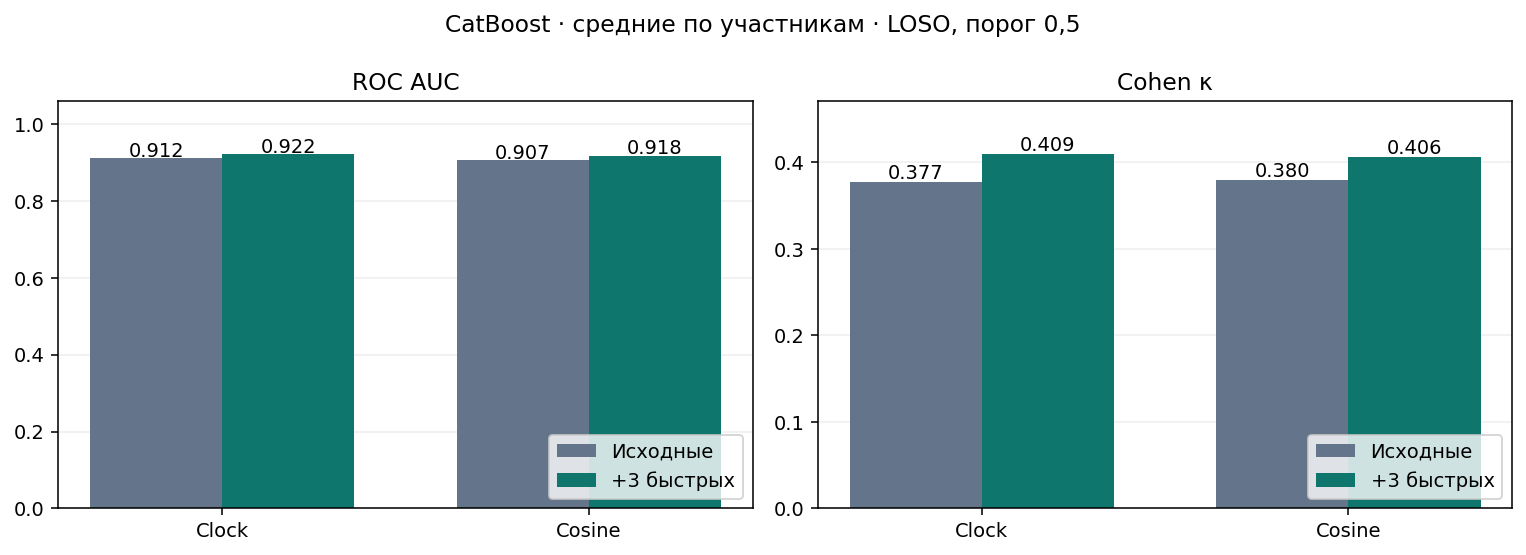

In [3]:
display(means.rename(columns={k: TEXTS[k] for k in means.columns}).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["auc", "kappa"]):
    for i, base in enumerate(["Clock", "Cosine"]):
        for extra, offset in [(False, -.18), (True, .18)]:
            key = "fast" if extra else "base"
            value = means.loc[feature_set(base, extra), metric]
            ax.bar(i + offset, value, width=.36, color=COLORS[key], label=TEXTS[key] if i == 0 else None)
            ax.text(i + offset, value + .004, f"{value:.3f}", ha="center")
    ax.set_xticks([0, 1], ["Clock", "Cosine"])
    ax.set_title(TEXTS[metric])
    ax.set_ylim(0, means[metric].max() * 1.15)
    ax.legend(loc="lower right")
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
fig.suptitle(TEXTS["means_title"])
fig.tight_layout()
fig.savefig(EXPORT_DIR / "mean_metrics.png", dpi=180)
plt.show()


**Результат:** дополнительные признаки улучшили средние AUC и κ в обоих вариантах времени.
Clock и Cosine — разные признаки: первый описывает циркадный ритм средствами проекта, второй — заданную временную косинусоиду.


## 2. За счёт чего меняется качество

Сравним распознавание обоих классов. При balanced-весах и пороге 0,5 модель часто предсказывает бодрствование; значения κ нельзя напрямую сравнивать с MLP, обученным по другому протоколу.


,"Accuracy · изменение, п.п.","Сон распознан · изменение, п.п.","Бодрствование распознано · изменение, п.п."
Время,,,
Clock,2.27,2.73,-0.32
Cosine,1.85,2.12,0.00


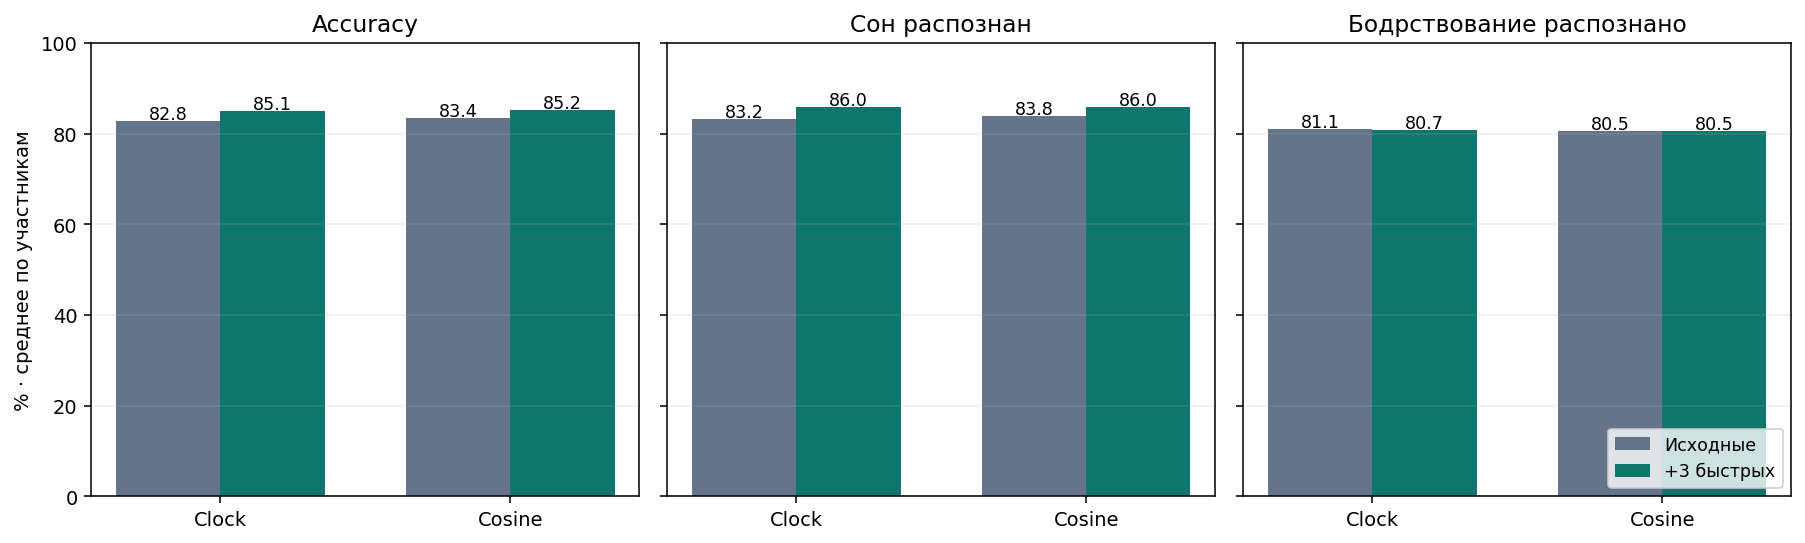

In [4]:
tradeoff = []
for base in ["Clock", "Cosine"]:
    a, b = means.loc[feature_set(base)], means.loc[feature_set(base, True)]
    tradeoff.append({"Время": base, **{TEXTS[m] + " · изменение, п.п.": 100 * (b[m] - a[m])
                    for m in ["accuracy", "sleep_correct", "wake_correct"]}})
display(pd.DataFrame(tradeoff).set_index("Время").round(2))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, metric in zip(axes, ["accuracy", "sleep_correct", "wake_correct"]):
    for i, base in enumerate(["Clock", "Cosine"]):
        for extra, offset in [(False, -.18), (True, .18)]:
            key = "fast" if extra else "base"
            value = 100 * means.loc[feature_set(base, extra), metric]
            ax.bar(i + offset, value, width=.36, color=COLORS[key], label=TEXTS[key] if i == 0 else None)
            ax.text(i + offset, value + .4, f"{value:.1f}", ha="center", fontsize=9)
    ax.set_xticks([0, 1], ["Clock", "Cosine"])
    ax.set_title(TEXTS[metric])
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("% · среднее по участникам")
axes[-1].legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "class_tradeoff.png", dpi=180)
plt.show()


При добавлении признаков основное изменение — **лучшее распознавание сна**. Среднее распознавание бодрствования почти сохраняется: для Clock оно немного снижается, для Cosine практически не меняется. Поэтому фраза «новые признаки улучшают распознавание бодрствования» не описывает этот результат при пороге 0,5.


## 3. Улучшение не одинаково для всех

Ниже — парные изменения κ у каждого человека. Положительное значение означает улучшение при добавлении признаков. Расчёт использует одних и тех же участников в обоих вариантах.


,Время,Метрика,Среднее изменение,Улучшилось участников,Всего,95% интервал · низ,95% интервал · верх
0,Clock,ROC AUC,0.0100,21,31,0.0015,0.0182
1,Clock,Cohen κ,0.0323,26,31,0.0126,0.0525
2,Cosine,ROC AUC,0.0108,21,31,0.0038,0.0177
3,Cosine,Cohen κ,0.0267,25,31,0.0093,0.0432


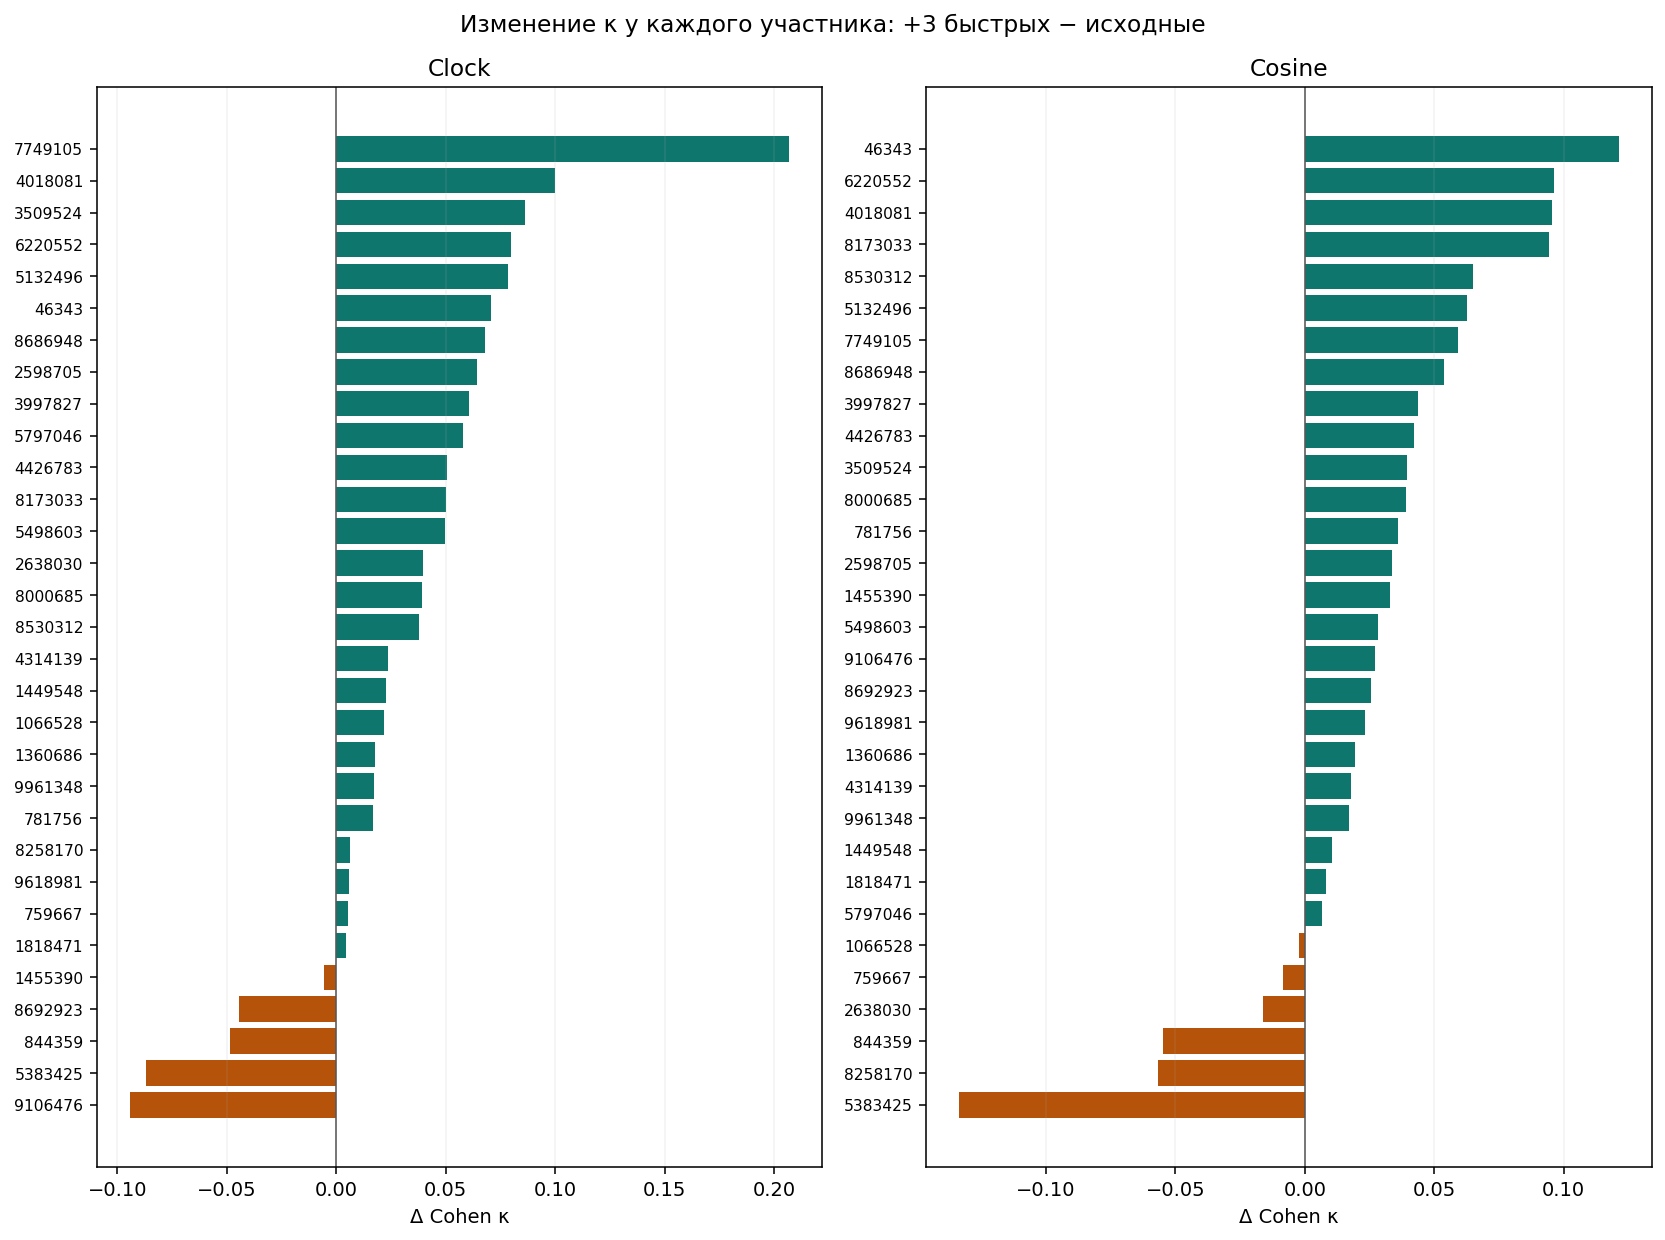

In [5]:
deltas = {}
analysis_rows = []
rng = np.random.default_rng(42)
for base in ["Clock", "Cosine"]:
    for metric in ["auc", "kappa"]:
        paired = participant[participant.feature_set.isin([feature_set(base), feature_set(base, True)])].pivot(index="subject", columns="feature_set", values=metric)
        delta = paired[feature_set(base, True)] - paired[feature_set(base)]
        deltas[(base, metric)] = delta
        draws = rng.choice(delta.to_numpy(), size=(10000, len(delta)), replace=True).mean(axis=1)
        lo, hi = np.quantile(draws, [.025, .975])
        analysis_rows.append({"Время": base, "Метрика": TEXTS[metric], "Среднее изменение": delta.mean(),
                              "Улучшилось участников": int((delta > 0).sum()), "Всего": len(delta),
                              "95% интервал · низ": lo, "95% интервал · верх": hi})
paired_analysis = pd.DataFrame(analysis_rows)
display(paired_analysis.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 9))
for ax, base in zip(axes, ["Clock", "Cosine"]):
    delta = deltas[(base, "kappa")].sort_values()
    colors = [COLORS["fast"] if v >= 0 else "#b45309" for v in delta]
    ax.barh(range(len(delta)), delta.to_numpy(), color=colors)
    ax.set_yticks(range(len(delta)), delta.index, fontsize=8)
    ax.axvline(0, color="#555555", linewidth=.8)
    ax.set_title(base)
    ax.set_xlabel("Δ " + TEXTS["kappa"])
    ax.grid(axis="x", alpha=.15)
fig.suptitle(TEXTS["delta_title"])
fig.tight_layout()
fig.savefig(EXPORT_DIR / "participant_deltas.png", dpi=180)
plt.show()


Интервалы получены описательным bootstrap по участникам: 10 000 повторных выборок парных различий. Они не учитывают весь предыдущий поиск признаков и моделей на этой выборке. Это оценка разброса наблюдаемого эффекта, а не подтверждение переноса на новую популяцию.


## 4. ROC и Precision–Recall

Теперь объединяем все отложенные эпохи. Здесь каждый человек получает вес в соответствии с длиной записи. Для PR положительный класс — **бодрствование**, чтобы показать качество распознавания редкого класса.


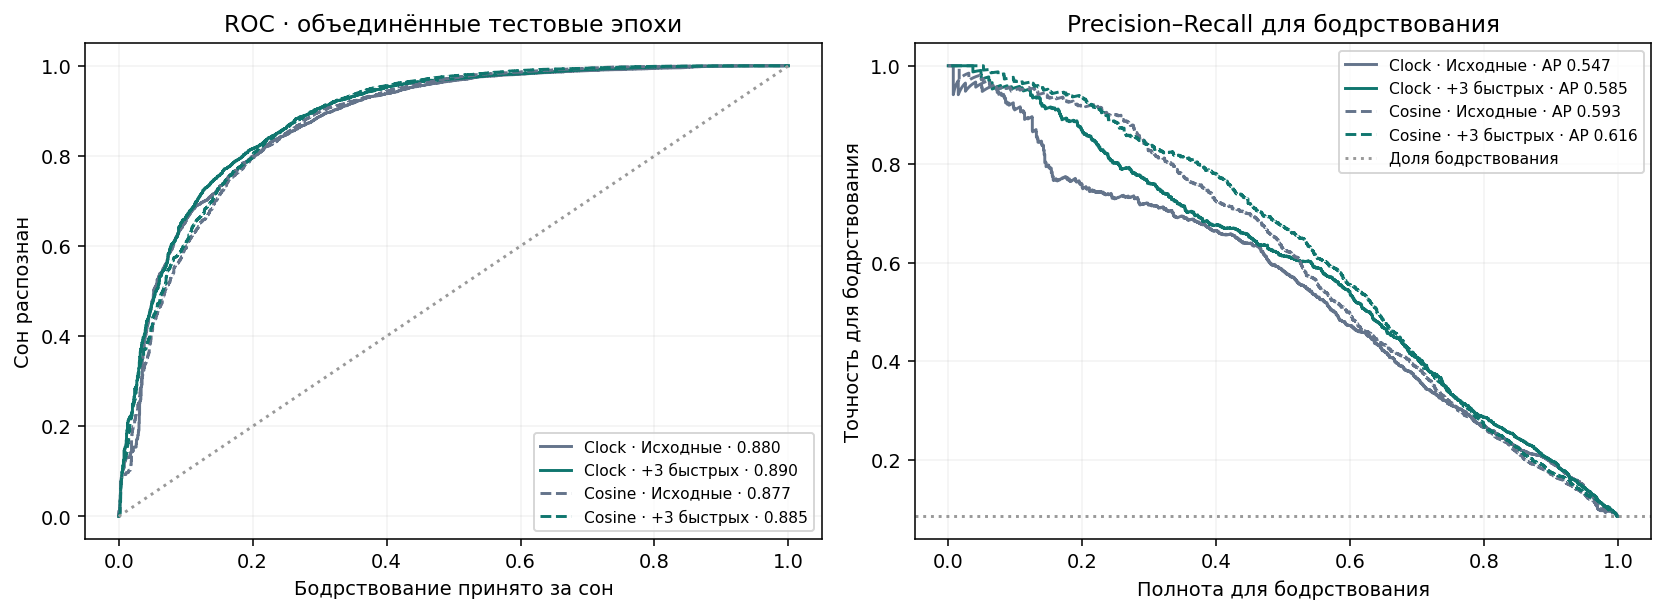

,Набор,AUC · все эпохи,AP бодрствования
0,"Motion, HR, Clock",0.8799,0.5466
1,"Motion, HR, Clock + быстрые",0.8896,0.5852
2,"Motion, HR, Cosine",0.8768,0.5932
3,"Motion, HR, Cosine + быстрые",0.8849,0.6157


In [6]:
y = arrays["y"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
curve_rows = []
for name in snapshot["manifest"]["feature_sets"]:
    p = arrays[name]
    color = COLORS["fast" if "быстрые" in name else "base"]
    style = "--" if "Cosine" in name else "-"
    auc = roc_auc_score(y, p)
    ap = average_precision_score(1 - y, 1 - p)
    fpr, tpr, _ = roc_curve(y, p)
    precision, recall, _ = precision_recall_curve(1 - y, 1 - p)
    axes[0].plot(fpr, tpr, color=color, linestyle=style, label=f"{name_for(name)} · {auc:.3f}")
    axes[1].plot(recall, precision, color=color, linestyle=style, label=f"{name_for(name)} · AP {ap:.3f}")
    curve_rows.append({"Набор": name, "AUC · все эпохи": auc, "AP бодрствования": ap})
axes[0].plot([0, 1], [0, 1], ":", color="#999999")
axes[1].axhline((1 - y).mean(), linestyle=":", color="#999999", label="Доля бодрствования")
axes[0].set(title=TEXTS["roc_title"], xlabel="Бодрствование принято за сон", ylabel="Сон распознан")
axes[1].set(title=TEXTS["pr_title"], xlabel="Полнота для бодрствования", ylabel="Точность для бодрствования")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "roc_pr.png", dpi=180)
plt.show()
display(pd.DataFrame(curve_rows).round(4))


**Почему AUC здесь отличается от первой таблицы?** Средний AUC по людям оценивает разделение классов внутри каждой записи. Объединённый AUC также сравнивает вероятности эпох разных участников. Это разные расчёты; нельзя смешивать их в одной строке сравнения. κ также нелинейна: κ общей матрицы ошибок отличается от среднего κ отдельных людей.


## 5. Матрицы ошибок при пороге 0,5

Строки — истинный класс, столбцы — предсказанный. Цвет и проценты нормированы по строке; абсолютное число эпох показано в каждой клетке.


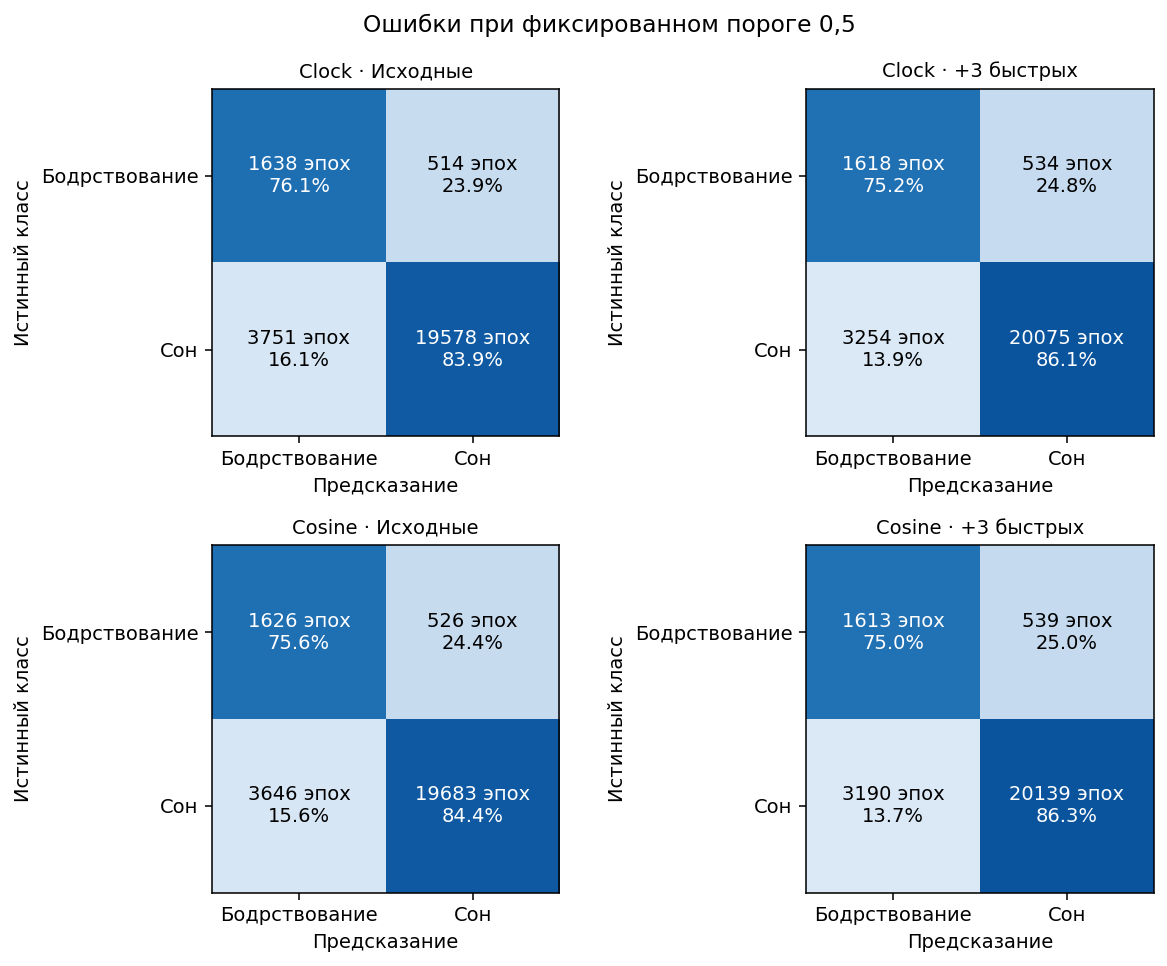

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, name in zip(axes.flat, snapshot["manifest"]["feature_sets"]):
    matrix = confusion_matrix(y, arrays[name] >= .5, labels=[0, 1])
    fractions = matrix / matrix.sum(axis=1, keepdims=True)
    ax.imshow(fractions, cmap="Blues", vmin=0, vmax=1)
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{matrix[row, col]} эпох\n{fractions[row, col]:.1%}", ha="center", va="center",
                    color="white" if fractions[row, col] > .5 else "black")
    ax.set_xticks([0, 1], ["Бодрствование", "Сон"])
    ax.set_yticks([0, 1], ["Бодрствование", "Сон"])
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Истинный класс")
    ax.set_title(name_for(name), fontsize=10)
fig.suptitle(TEXTS["confusion_title"])
fig.tight_layout()
fig.savefig(EXPORT_DIR / "confusion_matrices.png", dpi=180)
plt.show()


## 6. Описательные результаты при 90% распознанного сна

В исходном скрипте порог для этой таблицы выбирается **по истинным тестовым меткам**, чтобы получить заданную чувствительность. Это анализ возможного рабочего режима, как в таблицах статьи. Он не показывает результат заранее выбранного порога и не должен подменять оценку при 0,5.


In [8]:
display(pooled[["feature_set", "accuracy@90", "wake_correct@90", "kappa@90", "f1_wake@90"]].round(4))


,feature_set,accuracy@90,wake_correct@90,kappa@90,f1_wake@90
0,"Motion, HR, Clock",0.8814,0.6803,0.4308,0.4922
1,"Motion, HR, Clock + быстрые",0.8839,0.7086,0.4477,0.5076
2,"Motion, HR, Cosine",0.8827,0.6952,0.4397,0.5003
3,"Motion, HR, Cosine + быстрые",0.8836,0.7063,0.4462,0.5062


## Вывод

Три дополнительных признака улучшили CatBoost при обеих версиях временного признака. При пороге 0,5 улучшение главным образом связано с распознаванием сна; эффект различается между участниками.

Ограничения:

- Использованы фиксированные настройки на 100 деревьев; результаты не характеризуют все возможные настройки CatBoost.
- Выборка уже использовалась для исследования других моделей и признаков. Нужна независимая внешняя проверка.
- Медиана пульса и центрированные окна используют будущие данные: анализ предназначен для готовой записи.
- С прежним MLP числа напрямую не сопоставимы: отличаются разбиения, веса классов и настройки. Для сравнения моделей нужен общий протокол.
- Этот анализ оценивает три добавки вместе. Вклад каждого признака в прибавку качества отдельно не установлен.

## Веса и воспроизведение

Финальные модели и JSON с порядком входов лежат в [репозитории](https://github.com/AlisaPopova25/ai_school_october/tree/main/results/catboost_fast_features). Этот ноутбук не использует финальные веса для оценки и не запускает обучение.

Для повторного обучения в репозитории: `python repro/10_fast_features.py --models CatBoost`, затем `python repro/save_fast_catboost.py`.


In [9]:
# Сохранить все таблицы анализа рядом с графиками.
participant.to_csv(EXPORT_DIR / "participant_metrics.csv", index=False)
means.to_csv(EXPORT_DIR / "participant_mean_metrics.csv")
paired_analysis.to_csv(EXPORT_DIR / "paired_changes.csv", index=False)
pooled.to_csv(EXPORT_DIR / "pooled_metrics.csv", index=False)
print("Графики и таблицы сохранены в:", EXPORT_DIR)


Графики и таблицы сохранены в: C:\Users\Lenovo\Documents\ChatGPT\ПШ - 2\ai_school_october\results\catboost_fast_features\analysis_exports
